In [28]:
import pandas as pd
import numpy as np
import re
import os
import sys
import json

import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append("../functions/")
import networks


In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
with open("../data/Venturelli2018/generated/metid2metname.json") as json_file:
    metid2metname = json.load(json_file)

**Read and process experimental relative abundances**

In [4]:
abundances_exp_list = []

for file in os.listdir("../data/Venturelli2018/generated/communities_steadiercom/"):
    if file.endswith(".tsv"):
        abundance = pd.read_csv("../data/Venturelli2018/generated/communities_steadiercom/"+file,sep="\t",header=None)
        abundances_exp_list.append(abundance)
        
abundances_exp = pd.concat(abundances_exp_list)
abundances_exp.columns = ["community","member","abundance"]

abundances_exp = abundances_exp.set_index(["community","member"])["abundance"]
abundances_exp = abundances_exp.unstack().T

**Read and process simulated relative abundance**

In [5]:
abundance = {}

for file in os.listdir("../output/Venturelli2018/results_steadiercom/results_growth/"):
    if file.endswith(".tsv") and file.endswith("_abundance.tsv"):
        abundance[file[:-4]] = pd.read_csv("../output/Venturelli2018/results_steadiercom/results_growth/"+file,sep="\t")

abundance_df = pd.concat(abundance)
abundance_df = abundance_df.reset_index(drop=True)

**Read and process simulation interaction results**

In [6]:

# Identify compounds that are not of interest (part of M9)
media_db = pd.read_csv("https://raw.githubusercontent.com/cdanielmachado/carveme/refs/heads/master/carveme/data/input/media_db.tsv",sep="\t")
compounds = media_db[media_db.medium=="M9"].compound.values
compounds = list(compounds)
compounds.remove("glc__D")
m9_compounds = ["M_"+met+"__91__e__93__" for met in compounds]

# Read and join results
results_raw= {}

for file in os.listdir("../output/Venturelli2018/results_steadiercom/results_growth/"):
    if file.endswith(".tsv") and not file.endswith("_abundance.tsv"):
        results_raw[file[:-4]] = pd.read_csv("../output/Venturelli2018/results_steadiercom/results_growth/"+file,sep="\t")

results_raw_df = pd.concat(results_raw)
results_raw_df = results_raw_df.reset_index(drop=True)

# Add extra layers and remove uninteresting results
results = results_raw_df.copy()
results["mass_rate*frequency"] = results["frequency"]*results["mass_rate"]
results = results[~results.compound.isin(m9_compounds)] # REMOVED M9 COMPOUNDS

**Adjust results for simualted interactions**

*Original results - many samples are dominated by one species*

In [7]:
tot_samples = abundance_df.set_index(["sample","community"]).index.unique().shape[0]
tot_samples

26000

*Filter out the samples with only ONE dominating species*

In [8]:
abundance_df_reduced = abundance_df.copy()
counts = abundance_df_reduced[["sample","community"]].value_counts()
multiple_entries =counts[counts>1].index #Filtering...
abundance_df_reduced = abundance_df_reduced.set_index(["sample","community"]).loc[multiple_entries].reset_index()

*Filtering cuts away most of the samples*

In [9]:
inter_samples = abundance_df_reduced.set_index(["sample","community"]).index.unique().shape[0]
inter_samples

5283

*Frequency is off by*

In [10]:
conversion = 1/(inter_samples/tot_samples)
conversion

4.921446148021957

In [11]:
results_env = results[(results.donor!="environment") & (results.receiver!="environment") ].copy()
results_env.frequency=results_env.frequency*conversion

### Degree centrality (frequency)

In [17]:

centrality_metrics_comm= {}

for comm in results_env.community.unique():
    print(comm)
    results_comm = results_env[results_env.community==comm].copy()
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.01)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=False,degree_type="both")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["degree (data)"].unstack()
centrality =centrality.sort_index()


sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

centrality_sorted = centrality_sorted-centrality_sorted.T.loc[:,"NONE"].fillna(0)

PC-
FP-
BT-
CH-
EL-
DP-
BU-
ER-
CA-
BH-
BV-
NONE
BO-


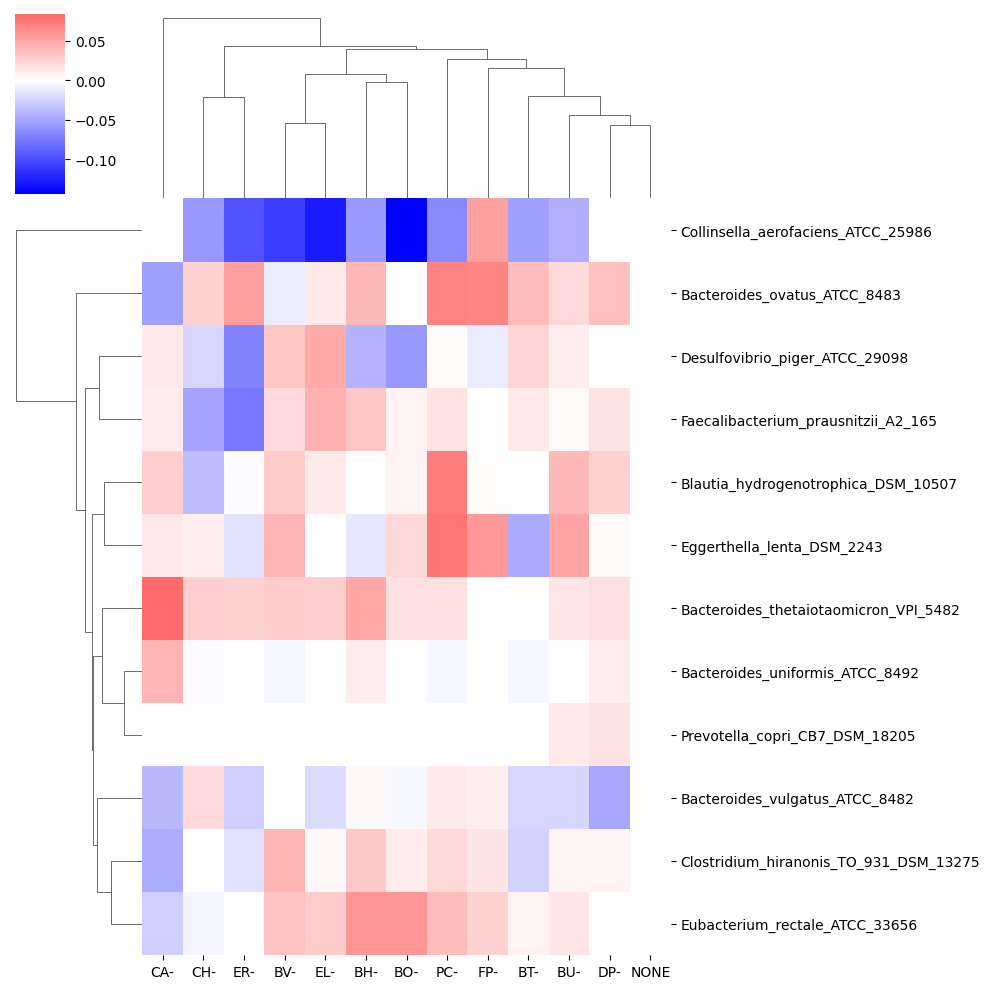

In [18]:

g = sns.clustermap(centrality_sorted.fillna(0).T,cmap="bwr",center=0)
#g.savefig("figures_meeting/clustermap_degree_gut.png", bbox_inches="tight")


### Closeness centrality (frequency)

In [32]:

centrality_metrics_comm= {}

for comm in results_env.community.unique():
    print(comm)
    results_comm = results_env[results_env.community==comm].copy()
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.05)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=True,degree_type="out")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["closeness (1/data)"].unstack()
centrality =centrality.sort_index()


sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

centrality_sorted = centrality_sorted-centrality_sorted.T.loc[:,"NONE"].fillna(0)

PC-
FP-
BT-
CH-
EL-
DP-
BU-
ER-
CA-
BH-
BV-
NONE
BO-


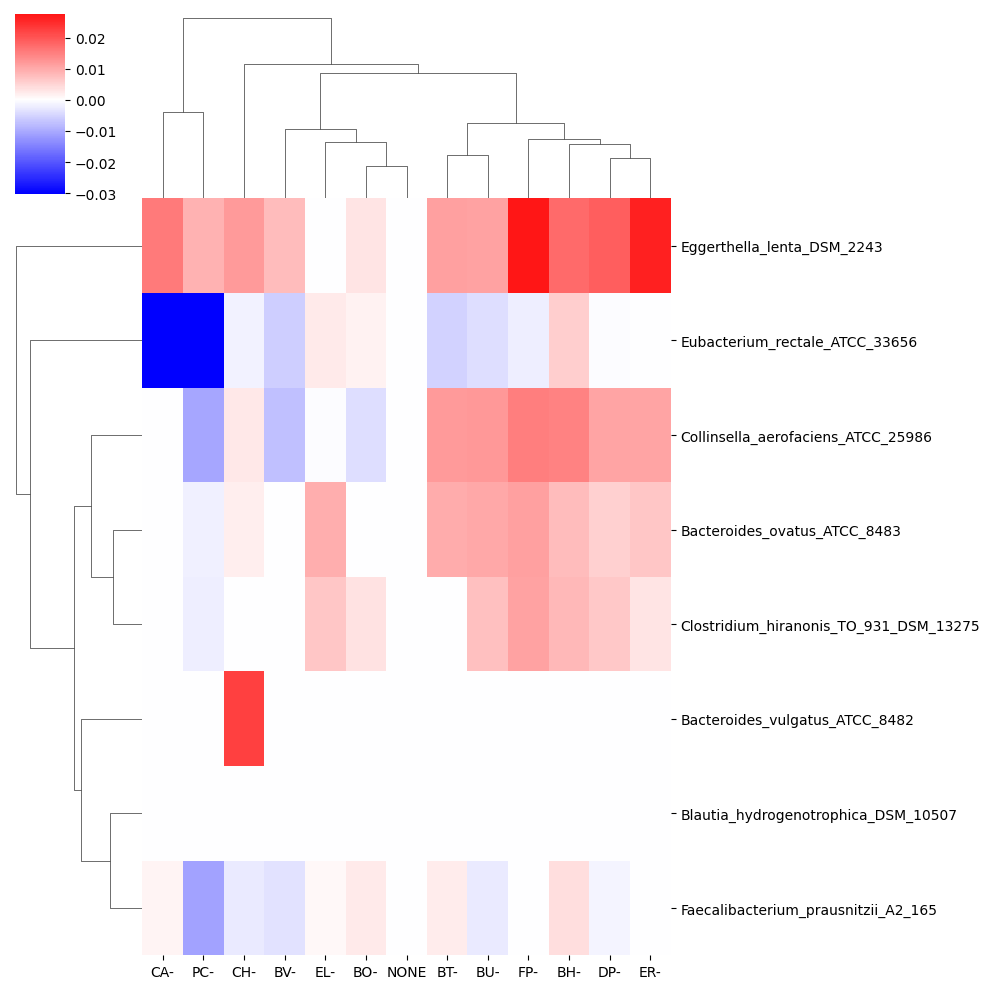

In [33]:

g = sns.clustermap(centrality_sorted.fillna(0).T,cmap="bwr",center=0)

#g.savefig("figures_meeting/clustermap_closeness_gut.png", bbox_inches="tight")


### Betweeness centrality (frequency)

In [36]:

centrality_metrics_comm= {}

for comm in results_env.community.unique():
    print(comm)
    results_comm = results_env[results_env.community==comm].copy()
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.01)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=True,degree_type="out")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["betweeness (1/data)"].unstack()
centrality =centrality.sort_index()


sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

centrality_sorted = centrality_sorted-centrality_sorted.T.loc[:,"NONE"].fillna(0)

PC-
FP-
BT-
CH-
EL-
DP-
BU-
ER-
CA-
BH-
BV-
NONE
BO-


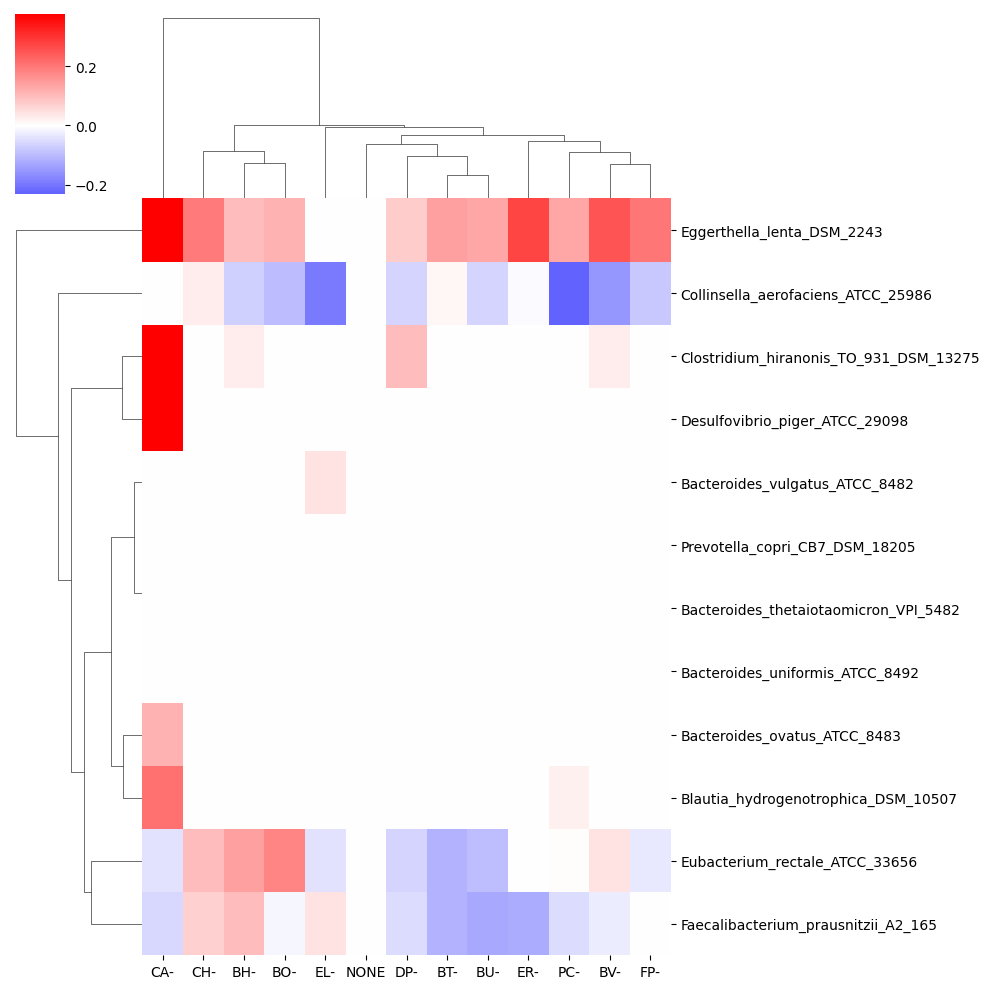

In [37]:
g = sns.clustermap(centrality_sorted.fillna(0).T,cmap="bwr",center=0)

In [23]:
don = results_env[["donor","compound","community","frequency"]].groupby(["donor","compound","community"]).mean()["frequency"].reset_index()
rec = results_env[["compound","receiver","community","frequency"]].groupby(["compound","receiver","community"]).mean()["frequency"].reset_index()

don.columns = ["A","B","community","frequency"]
rec.columns = ["A","B","community","frequency"]

don_rec_df = pd.concat([don,rec])
don_rec_df = don_rec_df.set_index(["community","A","B"])["frequency"]

/var/folders/mc/1rm74nkd4s78l46281nyt5wm0000gn/T/ipykernel_79305/3209849630.py:48: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_xticklabels(), rotation=90)
/var/folders/mc/1rm74nkd4s78l46281nyt5wm0000gn/T/ipykernel_79305/3209849630.py:48: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_xticklabels(), rotation=90)
/var/folders/mc/1rm74nkd4s78l46281nyt5wm0000gn/T/ipykernel_79305/3209849630.py:48: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_xticklabels(), rotation=90)


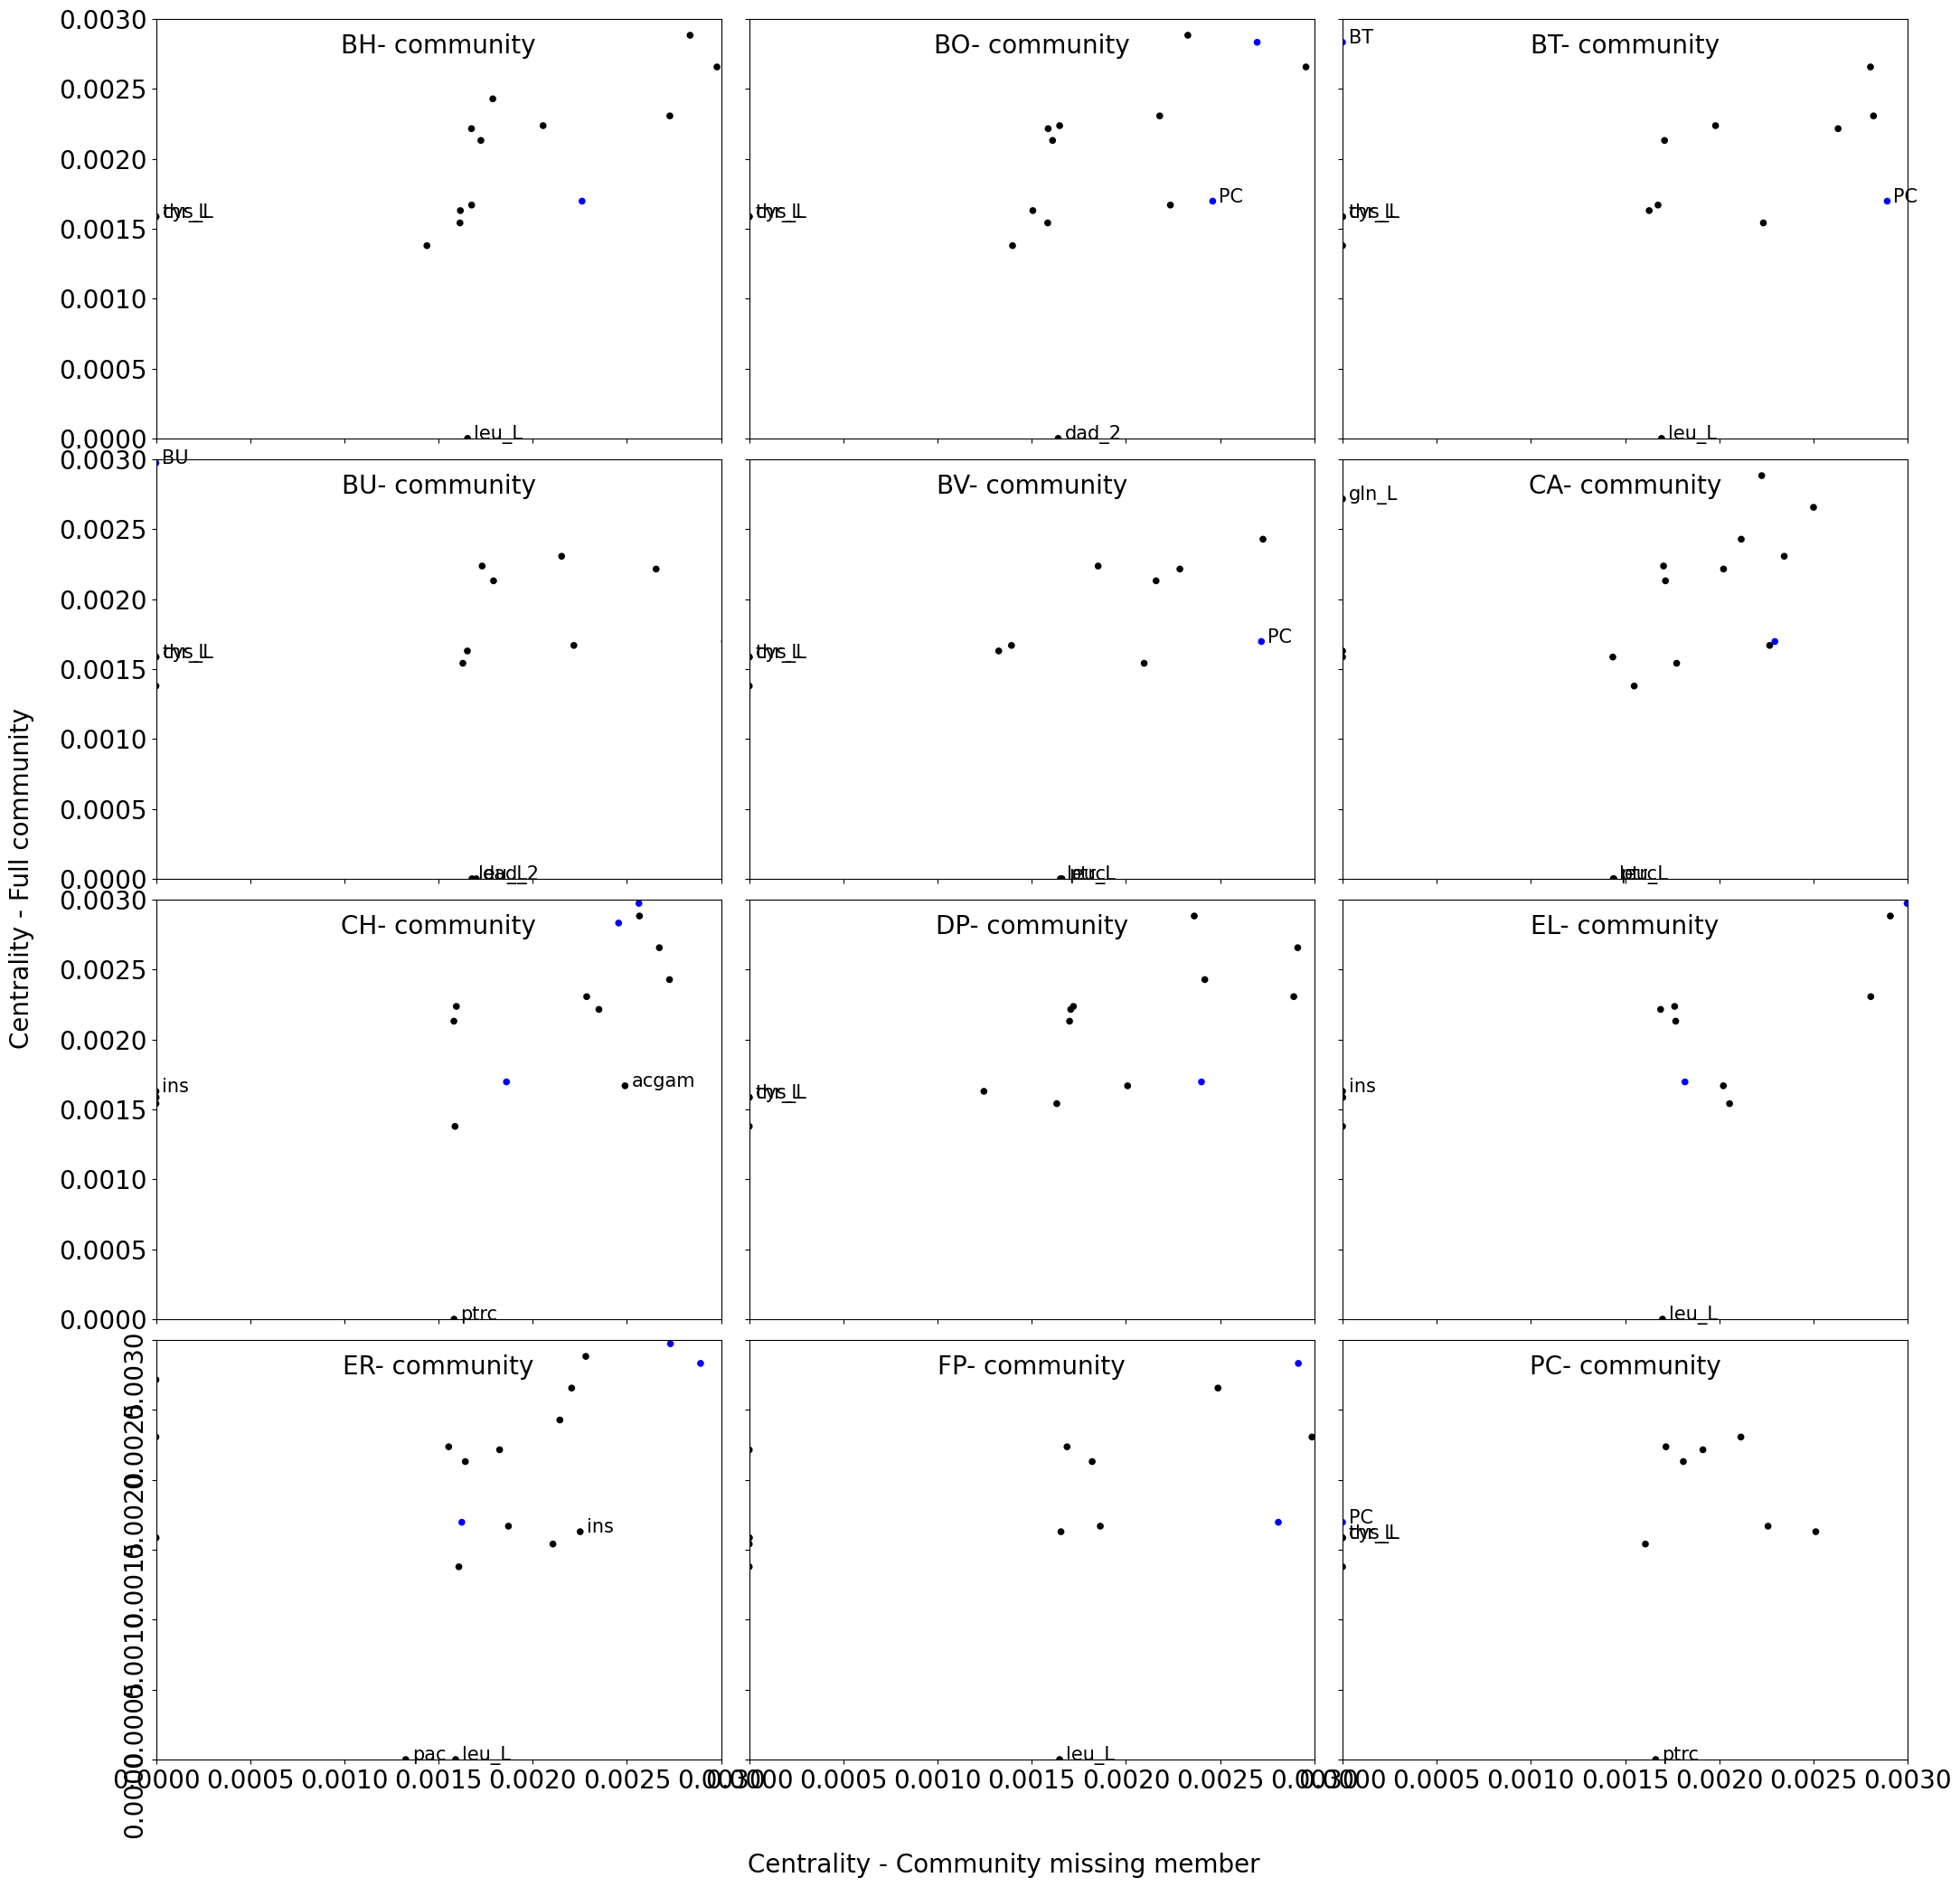

In [25]:
communities = [community_id for community_id in  results_env.community.sort_values().unique() if community_id!="NONE"]

metric = "closeness (1/data)"
fig,axs = plt.subplots(4,3,figsize=(25,25))
axs = axs.flatten()

bottom_row = ["ER-","FP-","PC-"]
left_col = ["BH-","BU-","CH-","ER-"]
ylim = 0.003

for i,community_id in enumerate(communities):
    ax = axs[i]
    
    NONE = networks.cooperation_centrality_metrics(don_rec_df.xs("NONE"))
    COMM = networks.cooperation_centrality_metrics(don_rec_df.xs(community_id))

    centrality_df = pd.concat([NONE[metric],COMM[metric]],axis=1)
    centrality_df.columns = ["NONE",community_id]
    centrality_df = centrality_df.fillna(0)

    centrality_df["is_met"] = centrality_df.index.str.startswith("M_")
    centrality_df.index = centrality_df.index.map(lambda x:re.sub(r"^M_(.*)__91__e__93__$", r"\1", x))
    centrality_df.index = centrality_df.index.map(lambda x:x if centrality_df.loc[x,"is_met"] else x.split("_")[0][0].upper()+x.split("_")[1][0].upper())
    
    colors = np.where(centrality_df["is_met"],'black','blue')


    centrality_df.plot(kind="scatter",y="NONE",x=community_id,ax = ax,c=colors)#,logy=True,logx=True)
    centrality_df["diff"] = centrality_df[community_id]-centrality_df["NONE"]

    lower, upper = centrality_df["diff"].quantile([0.05, 0.95])
    significant_nodes = centrality_df[(centrality_df["diff"] < lower) | (centrality_df["diff"] > upper)]

    for node, row in significant_nodes.iterrows():
        ax.annotate(node, (row[community_id], row["NONE"]), textcoords="offset points", xytext=(5,-1), ha='left',fontsize=15)
    
    
    ax.set_ylim([0,ylim])
    ax.set_xlim([0,ylim])
    
    #if community_id=="BT":
        #sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

    if community_id not in bottom_row:
        ax.tick_params(labelbottom=False) 
    else:
        ax.tick_params(labelsize=20)
        ax.set_yticklabels(ax.get_xticklabels(), rotation=90) 

    if community_id not in left_col:
        ax.tick_params(labelleft=False)

    else:    
        #plt.setp(ax.get_yticklabels()[-1], visible=False)
        ax.tick_params(labelsize=20)

    ax.set_xlabel("")
    ax.set_ylabel("")
    
    ax.set_title(community_id + " community", y=0.9,fontsize=20)
    
    #sns.despine(ax=ax, left=despine_left,bottom=False,right=True,top=True)
    
fig.text(0.5, 0.06, 'Centrality - Community missing member', ha='center',fontsize=20)
fig.text(0.06, 0.5, 'Centrality - Full community', va='center', rotation='vertical',fontsize=20)

plt.subplots_adjust(wspace=0.05, hspace=0.05)
plt.savefig("test.png")

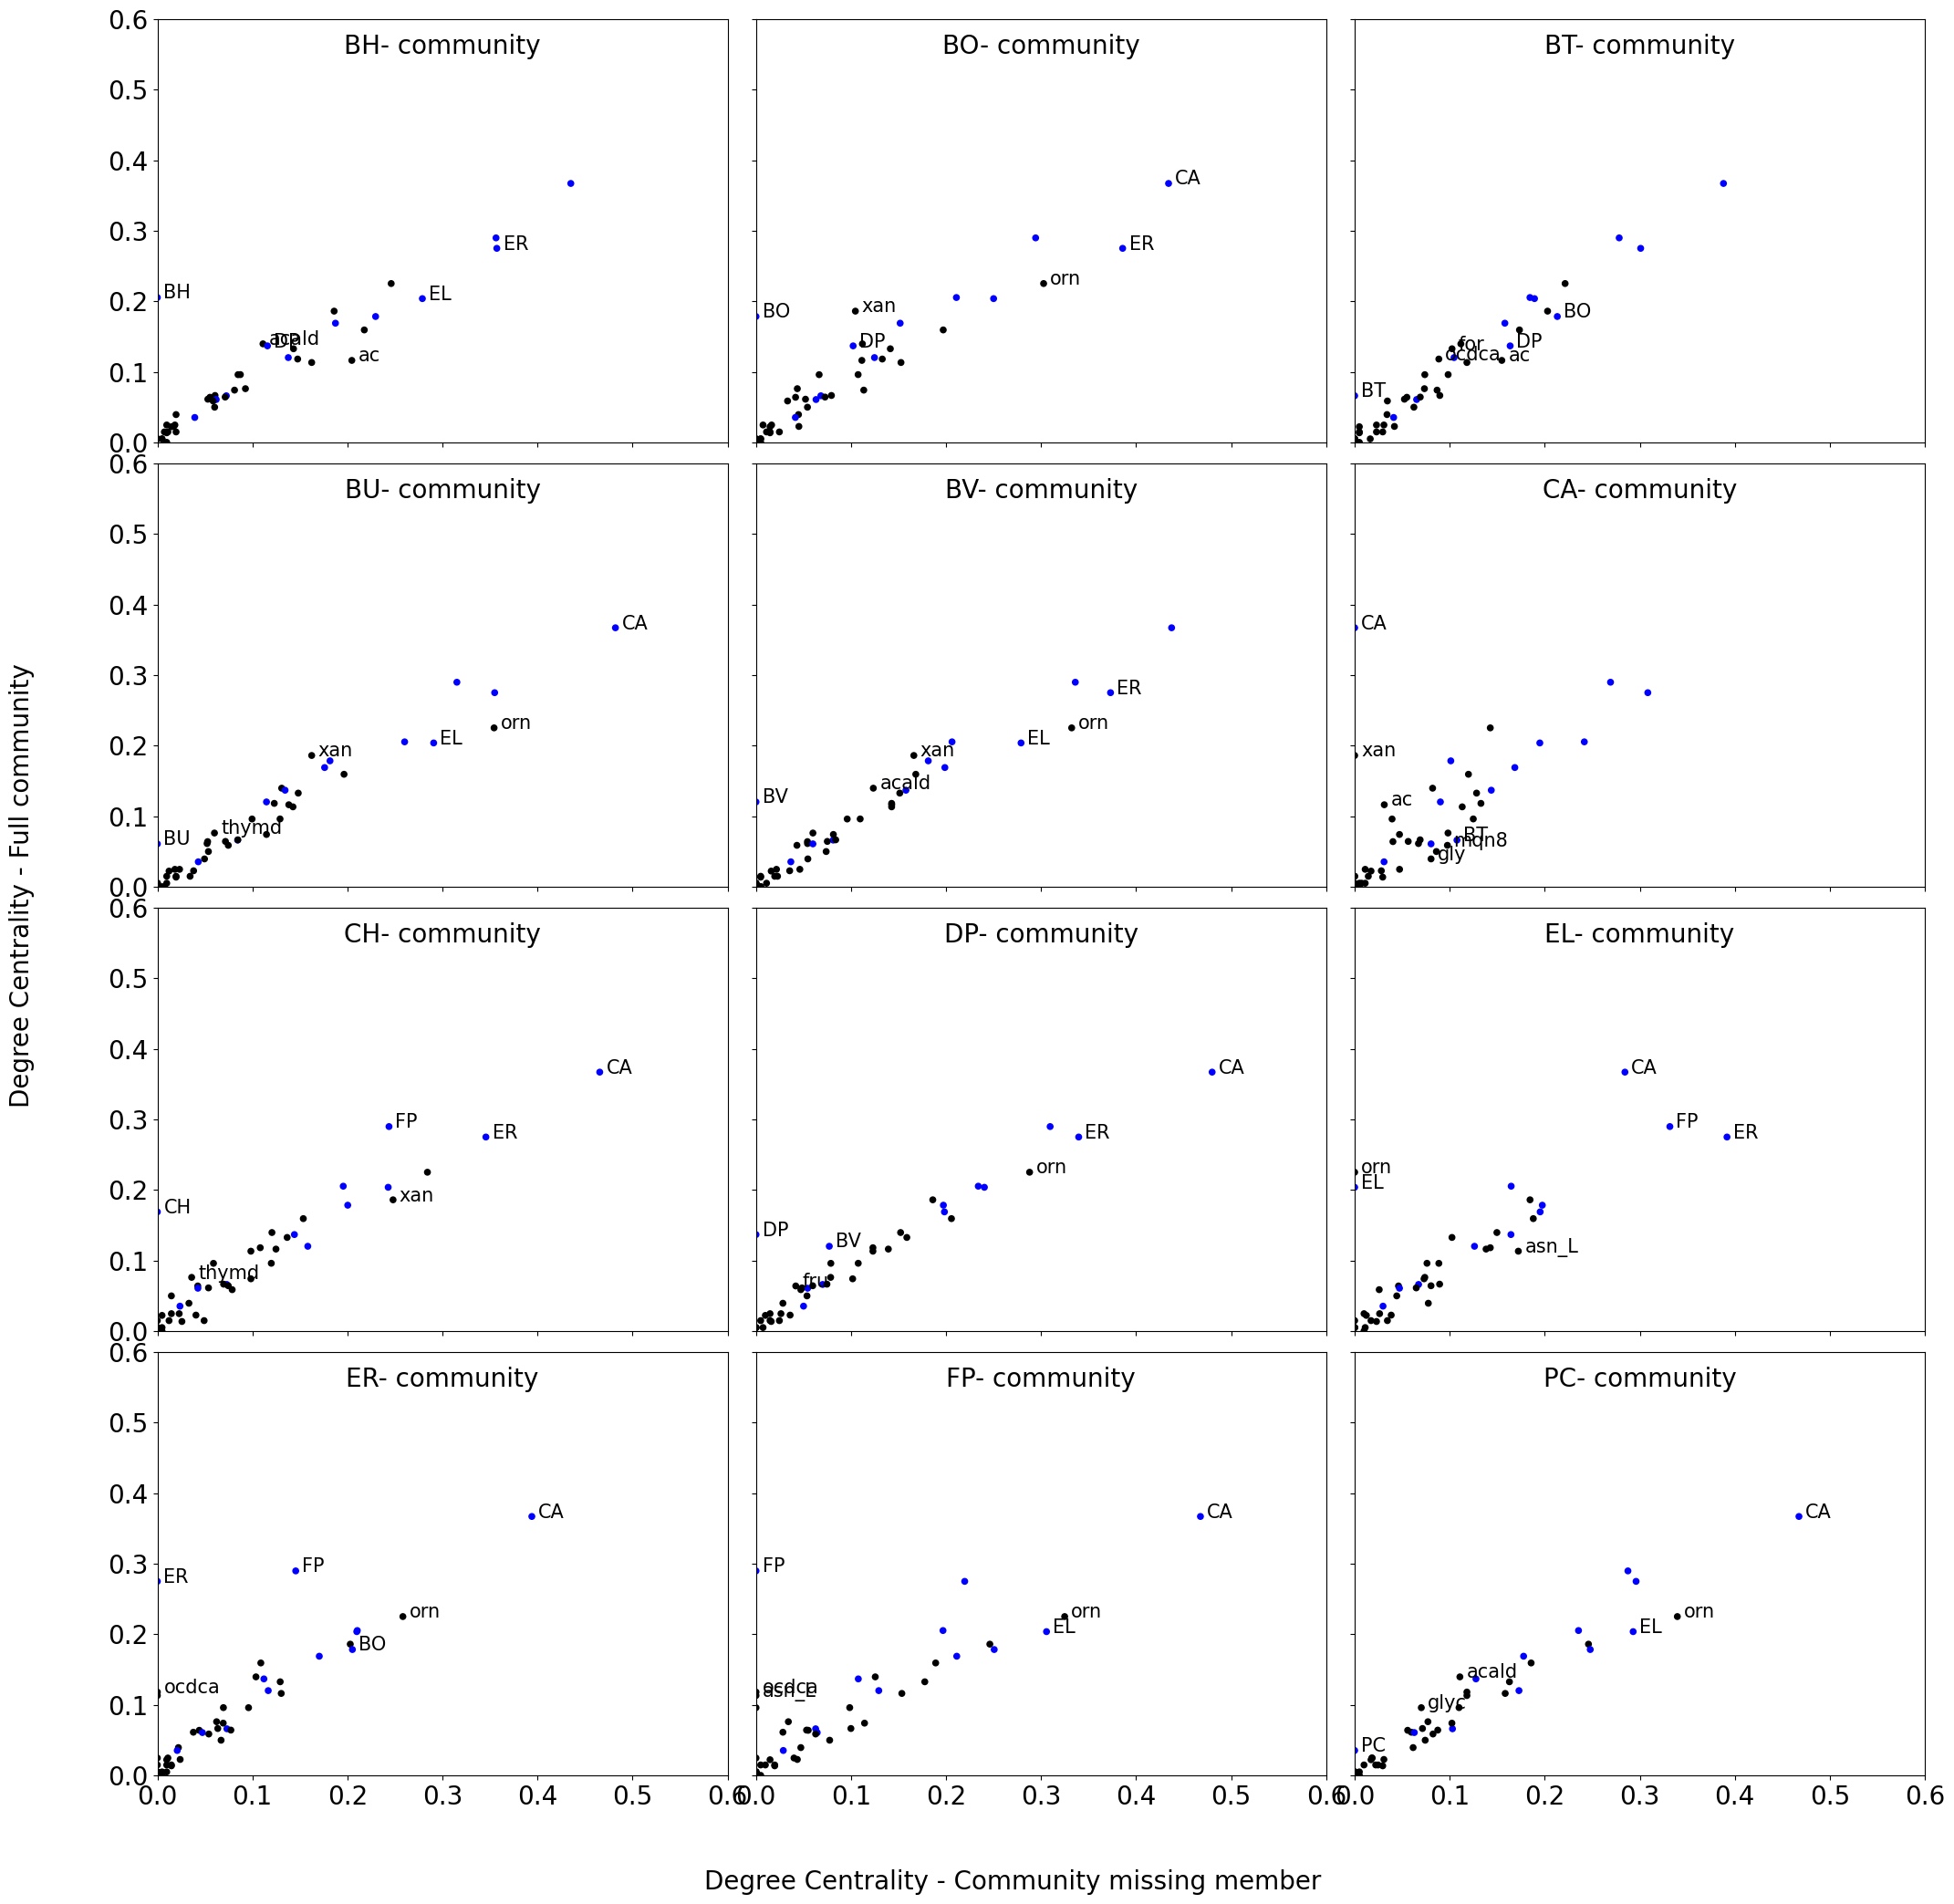

In [26]:
communities = [community_id for community_id in  results_env.community.sort_values().unique() if community_id!="NONE"]

metric = "degree (data)"
SP_centrality = False
fig,axs = plt.subplots(4,3,figsize=(25,25))
axs = axs.flatten()

bottom_row = ["ER-","FP-","PC-"]
left_col = ["BH-","BU-","CH-","ER-"]
ylim = 0.6

for i,community_id in enumerate(communities):
    ax = axs[i]
    
    NONE = networks.cooperation_centrality_metrics(don_rec_df.xs("NONE"),SP_centrality=SP_centrality)
    COMM = networks.cooperation_centrality_metrics(don_rec_df.xs(community_id),SP_centrality=SP_centrality)

    centrality_df = pd.concat([NONE[metric],COMM[metric]],axis=1)
    centrality_df.columns = ["NONE",community_id]
    centrality_df = centrality_df.fillna(0)

    centrality_df["is_met"] = centrality_df.index.str.startswith("M_")
    centrality_df.index = centrality_df.index.map(lambda x:re.sub(r"^M_(.*)__91__e__93__$", r"\1", x))
    centrality_df.index = centrality_df.index.map(lambda x:x if centrality_df.loc[x,"is_met"] else x.split("_")[0][0].upper()+x.split("_")[1][0].upper())
    
    colors = np.where(centrality_df["is_met"],'black','blue')


    centrality_df.plot(kind="scatter",y="NONE",x=community_id,ax = ax,c=colors)#,logy=True,logx=True)
    centrality_df["diff"] = centrality_df[community_id]-centrality_df["NONE"]

    lower, upper = centrality_df["diff"].quantile([0.05, 0.95])
    significant_nodes = centrality_df[(centrality_df["diff"] < lower) | (centrality_df["diff"] > upper)]

    for node, row in significant_nodes.iterrows():
        ax.annotate(node, (row[community_id], row["NONE"]), textcoords="offset points", xytext=(5,-1), ha='left',fontsize=15)
    
    
    ax.set_ylim([0,ylim])
    ax.set_xlim([0,ylim])
    

    if community_id not in bottom_row:
        ax.tick_params(labelbottom=False) 
    else:
        ax.tick_params(labelsize=20)
        #ax.set_yticklabels(ax.get_xticklabels(), rotation=90) 

    if community_id not in left_col:
        ax.tick_params(labelleft=False)

    else:    
        #plt.setp(ax.get_yticklabels()[-1], visible=False)
        ax.tick_params(labelsize=20)

    ax.set_xlabel("")
    ax.set_ylabel("")
    
    ax.set_title(community_id + " community", y=0.9,fontsize=20)
    
    #sns.despine(ax=ax, left=despine_left,bottom=False,right=True,top=True)
    
fig.text(0.5, 0.06, 'Degree Centrality - Community missing member', ha='center',fontsize=20)
fig.text(0.06, 0.5, 'Degree Centrality - Full community', va='center', rotation='vertical',fontsize=20)

plt.subplots_adjust(wspace=0.05, hspace=0.05)
#plt.savefig("figures_meeting/degree_centrality_met_mem.png",bbox_inches="tight")

# E. coli culture

In [41]:
abundance = {}

for file in os.listdir("../output/Guillen2021/results_steadiercom/results_growth/"):
    if file.endswith(".tsv") and file.endswith("_abundance.tsv"):
        abundance[file[:-4]] = pd.read_csv("../output/Guillen2021/results_steadiercom/results_growth/"+file,sep="\t")
abundance_df = pd.concat(abundance)
abundance_df = abundance_df.reset_index(drop=True)
abundance_df

,sample,member,relative_abundance,community,medium
0,0,mutant_panZ,0.007743,ecoli_auxotrophs,M9
1,0,mutant_icd,0.992257,ecoli_auxotrophs,M9
2,1,mutant_panD,0.000269,ecoli_auxotrophs,M9
3,1,mutant_bioF,0.999731,ecoli_auxotrophs,M9
4,2,mutant_panZ,0.000223,ecoli_auxotrophs,M9
...,...,...,...,...,...
9270,3997,mutant_bioH,0.925844,ecoli_auxotrophs,M9
9271,3998,mutant_panD,0.000293,ecoli_auxotrophs,M9
9272,3998,mutant_bioF,0.999707,ecoli_auxotrophs,M9
9273,3999,mutant_cysW,0.000227,ecoli_auxotrophs,M9


**Read and process simulation interaction results**

In [ ]:

# Read and join results
results_raw= {}

results_raw_df = pd.read_csv("../output/Guillen2021/results_steadiercom/results_growth/ecoli_mutants.tsv",sep="\t")

# Add extra layers and remove uninteresting results
results = results_raw_df.copy()
results["mass_rate*frequency"] = results["frequency"]*results["mass_rate"]
results

,donor,receiver,compound,mass_rate,rate,frequency,community,medium,mass_rate*frequency
0,mutant_bioF,environment,M_5dglcn_e,1.071294e+00,5.546978e+00,0.00725,ecoli_auxotrophs,M9,7.766882e-03
1,mutant_icd,environment,M_5dglcn_e,8.959884e-01,4.639276e+00,0.01150,ecoli_auxotrophs,M9,1.030387e-02
2,mutant_panD,environment,M_5dglcn_e,8.666403e-01,4.487316e+00,0.01050,ecoli_auxotrophs,M9,9.099723e-03
3,mutant_bioC,environment,M_5dglcn_e,8.637027e-01,4.472106e+00,0.00600,ecoli_auxotrophs,M9,5.182216e-03
4,mutant_bioC,mutant_icd,M_5dglcn_e,8.494207e-01,4.398156e+00,0.00025,ecoli_auxotrophs,M9,2.123552e-04
...,...,...,...,...,...,...,...,...,...
3032,mutant_panD,environment,M_val__L_e,1.356444e-10,1.157910e-09,0.05675,ecoli_auxotrophs,M9,7.697817e-12
3033,mutant_cysW,environment,M_ala__D_e,1.339923e-10,1.503962e-09,0.02725,ecoli_auxotrophs,M9,3.651291e-12
3034,mutant_bioF,environment,M_indole_e,1.270300e-10,1.084359e-09,0.01575,ecoli_auxotrophs,M9,2.000723e-12
3035,environment,mutant_bioC,M_gly_e,1.109415e-10,1.477911e-09,0.02225,ecoli_auxotrophs,M9,2.468448e-12


*Original results - many samples are dominated by one species*

In [43]:
tot_samples = abundance_df.set_index(["sample","community"]).index.unique().shape[0]
tot_samples

4000

*Filter out the samples with only ONE dominating species*

In [44]:
abundance_df_reduced = abundance_df.copy()
counts = abundance_df_reduced[["sample","community"]].value_counts()
multiple_entries =counts[counts>1].index #Filtering...
abundance_df_reduced = abundance_df_reduced.set_index(["sample","community"]).loc[multiple_entries].reset_index()

*Filtering cuts away most of the samples*

In [45]:
inter_samples = abundance_df_reduced.set_index(["sample","community"]).index.unique().shape[0]
inter_samples

4000

*Frequency is off by*

In [46]:
conversion = 1/(inter_samples/tot_samples)
conversion

1.0

In [47]:
results_env = results[(results.donor!="environment") & (results.receiver!="environment") ].copy()

results_env.frequency=results_env.frequency*conversion
results_env

,donor,receiver,compound,mass_rate,rate,frequency,community,medium,mass_rate*frequency
4,mutant_bioC,mutant_icd,M_5dglcn_e,8.494207e-01,4.398156e+00,0.00025,ecoli_auxotrophs,M9,2.123552e-04
7,mutant_bioC,mutant_bioH,M_glcn_e,7.945673e-01,4.071637e+00,0.00025,ecoli_auxotrophs,M9,1.986418e-04
14,mutant_panD,mutant_panZ,M_glcn_e,5.287102e-01,2.709293e+00,0.00075,ecoli_auxotrophs,M9,3.965326e-04
34,mutant_bioH,mutant_bioF,M_lac__D_e,2.947927e-01,3.309682e+00,0.00025,ecoli_auxotrophs,M9,7.369818e-05
41,mutant_icd,mutant_bioC,M_glcn_e,2.517602e-01,1.290106e+00,0.00125,ecoli_auxotrophs,M9,3.147003e-04
...,...,...,...,...,...,...,...,...,...
2726,mutant_panD,mutant_bioF,M_dha_e,1.286105e-07,1.427773e-06,0.00025,ecoli_auxotrophs,M9,3.215264e-11
2727,mutant_bioC,mutant_bioF,M_lac__D_e,1.152107e-07,1.293488e-06,0.00025,ecoli_auxotrophs,M9,2.880267e-11
2729,mutant_cysW,mutant_bioH,M_dha_e,9.032484e-08,1.002744e-06,0.00025,ecoli_auxotrophs,M9,2.258121e-11
2734,mutant_bioH,mutant_bioF,M_co2_e,7.222246e-08,1.641065e-06,0.00025,ecoli_auxotrophs,M9,1.805562e-11
